# Day 35 — Yes or No
## Logistic regression

**Prepared & presented by Srinivasa Sai Chava**  ·  Boston University

---

Everything so far predicted a **number**. Today the answer is a **category**: pass or
fail, fraud or not, placed or not.

You already have every piece of this:

- the **line** is Day 34's, unchanged
- the idea of a **cost function** and of **gradient descent** is yesterday's, unchanged

Today adds exactly two things: a way to turn any number into a probability, and a cost
function that is honest about confident mistakes.

| Part | What we do |
|---|---|
| **1** | Why a straight line cannot answer a yes/no question |
| **2** | The sigmoid — squashing any number into 0 to 1 |
| **3** | Why squared error is the wrong cost, and what replaces it |
| **4** | Reading the answer: odds, boundaries, and the cut-off |
| **5** | Doing it for real on 800 students |

> **A note on the name.** Despite "regression" in the title, logistic regression is a
> **classifier**. The name comes from the line hiding inside it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, log_loss

import warnings
warnings.simplefilter("ignore")

plt.rcParams["figure.figsize"] = (8, 3.4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["font.size"] = 11

print("ready")

ready


---
# Part 1 · Why a line will not do

## 1.1 · Ten students, and a yes/no answer

Same question as Day 33 — but instead of a mark out of 100, we only recorded whether
they passed.

In [2]:
hours = np.array([1., 2, 3, 4, 5, 6, 7, 8, 9, 10])
passed = np.array([0., 0, 0, 0, 1, 0, 1, 1, 1, 1])     # 1 = passed, 0 = failed

students = pd.DataFrame({"hours": hours, "passed": passed.astype(int)})
students.T

,0,1,2,3,4,5,6,7,8,9
hours,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0
passed,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0


Note the two awkward ones: somebody passed on 5 hours, somebody failed on 6. **Real data
always looks like this**, and a model that gets all ten right would be memorising.

## 1.2 · The obvious attempt: fit a line anyway

In [3]:
line = LinearRegression().fit(hours.reshape(-1, 1), passed)

print(f"the line: y = {line.coef_[0]:.4f} × hours + {line.intercept_:.4f}")
print()
for h in [0.5, 2, 5, 9, 12, 15]:
    print(f"   {h:>4} hours  ->  {line.predict([[h]])[0]:>7.3f}")

the line: y = 0.1394 × hours + -0.2667

    0.5 hours  ->   -0.197
      2 hours  ->    0.012
      5 hours  ->    0.430
      9 hours  ->    0.988
     12 hours  ->    1.406
     15 hours  ->    1.824


**A probability of −0.25. A probability of 2.17.**

Neither of those means anything. A line is a ramp that never stops; probabilities live
strictly between 0 and 1. Those two facts cannot both hold.

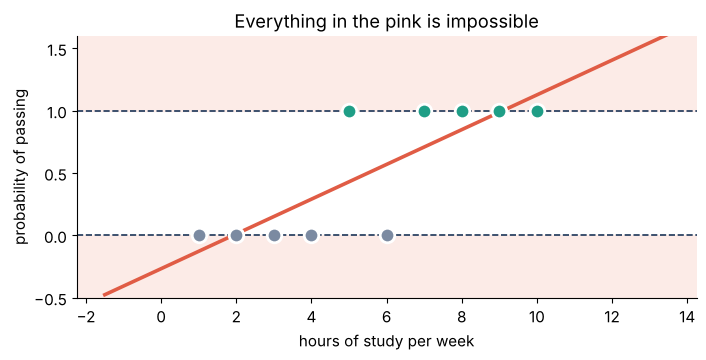

In [4]:
g = np.linspace(-1.5, 13.5, 100)

plt.plot(g, line.predict(g.reshape(-1, 1)), color="#E05C45", lw=2.6)
plt.scatter(hours[passed == 0], passed[passed == 0], s=110, color="#7B8AA1",
            zorder=5, edgecolor="white", lw=2)
plt.scatter(hours[passed == 1], passed[passed == 1], s=110, color="#1F9E86",
            zorder=5, edgecolor="white", lw=2)
plt.axhline(1, color="#1B3558", lw=1.2, ls="--")
plt.axhline(0, color="#1B3558", lw=1.2, ls="--")
plt.axhspan(1, 2.2, color="#FCEBE7")
plt.axhspan(-1.0, 0, color="#FCEBE7")
plt.ylim(-0.5, 1.6)
plt.xlabel("hours of study per week"); plt.ylabel("probability of passing")
plt.title("Everything in the pink is impossible")
plt.show()

## 1.3 · So what do we actually want?

1. **A number between 0 and 1** — a probability, not a bare verdict. "This student has a
   0.72 chance" is far more useful than "pass".
2. **That can never escape** — however extreme the input.
3. **Still built on a line** — we want to keep the coefficients, the speed and the
   interpretability of Day 34.

**Keep the line. Then squash its output.**

---
# Part 2 · Squashing it into 0 to 1

## 2.1 · The sigmoid

One function does the whole job:

$$ p = \frac{1}{1 + e^{-z}} $$

In [5]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

for z in [-1000, -6, -2, -1, 0, 1, 2, 6, 1000]:
    print(f"   sigmoid({z:>6}) = {sigmoid(z):.4f}")

   sigmoid( -1000) = 0.0000
   sigmoid(    -6) = 0.0025
   sigmoid(    -2) = 0.1192
   sigmoid(    -1) = 0.2689
   sigmoid(     0) = 0.5000
   sigmoid(     1) = 0.7311
   sigmoid(     2) = 0.8808
   sigmoid(     6) = 0.9975
   sigmoid(  1000) = 1.0000


**Check the middle one by hand:** at z = 0, e⁰ = 1, so p = 1/(1+1) = **exactly 0.5**.

And look at the two extremes: −1000 gives 0.0000, +1000 gives 1.0000. It gets
arbitrarily close to the edges but **can never reach them**, let alone pass them.

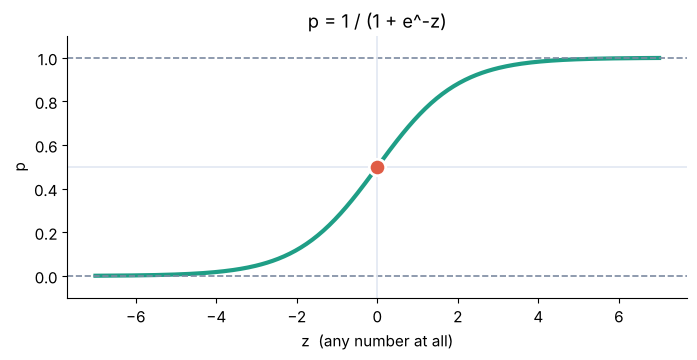

In [6]:
z = np.linspace(-7, 7, 300)

plt.plot(z, sigmoid(z), color="#1F9E86", lw=3)
plt.axhline(1, color="#7B8AA1", lw=1.2, ls="--")
plt.axhline(0, color="#7B8AA1", lw=1.2, ls="--")
plt.axhline(0.5, color="#E2E8F2", lw=1.2)
plt.axvline(0, color="#E2E8F2", lw=1.2)
plt.scatter([0], [0.5], s=140, color="#E05C45", zorder=6, edgecolor="white", lw=2)
plt.ylim(-0.1, 1.1)
plt.xlabel("z  (any number at all)"); plt.ylabel("p")
plt.title("p = 1 / (1 + e^-z)")
plt.show()

## 2.2 · The whole model, in three steps

| Step | What happens | Range |
|---|---|---|
| **1** | `z = w₁x₁ + w₂x₂ + … + b` — **this is Day 34, unchanged** | −∞ to +∞ |
| **2** | `p = 1 / (1 + e⁻ᶻ)` | 0 to 1 |
| **3** | `p ≥ 0.5 → yes`, `p < 0.5 → no` | yes / no |

Step 1 is multiple linear regression. **Steps 2 and 3 are all that is new today.**

## 2.3 · Fit it

In [7]:
model = LogisticRegression().fit(hours.reshape(-1, 1), passed)

w = model.coef_[0][0]
b = model.intercept_[0]

print(f"coefficient : {w:.6f}")
print(f"intercept   : {b:.6f}")
print()
print(f"the 0.5 boundary is at hours = -b/w = {-b/w:.4f}")

coefficient : 0.905905
intercept   : -4.982759

the 0.5 boundary is at hours = -b/w = 5.5003


### `p = sigmoid(0.906 × hours − 4.983)`, and the boundary is **5.5 hours**

Why is the boundary at −b/w? Because p = 0.5 happens exactly when z = 0, and
z = 0.906 × hours − 4.983 = 0 when hours = 4.983 / 0.906 = 5.5.

## 2.4 · Walk one student through by hand

In [8]:
h = 7
z = w*h + b
p = sigmoid(z)

print(f"step 1:  z = {w:.3f} × {h} + ({b:.3f}) = {z:.3f}")
print(f"step 2:  p = 1 / (1 + e^-{z:.3f}) = {p:.4f}")
print(f"step 3:  {p:.4f} >= 0.5, so we predict PASS")
print()
print("sklearn:", round(model.predict_proba([[7]])[0][1], 4))

step 1:  z = 0.906 × 7 + (-4.983) = 1.359
step 2:  p = 1 / (1 + e^-1.359) = 0.7955
step 3:  0.7955 >= 0.5, so we predict PASS

sklearn: 0.7955


In [9]:
table = pd.DataFrame({"hours": hours, "truth": passed.astype(int)})
table["z"] = (w*hours + b).round(3)
table["p"] = sigmoid(w*hours + b).round(4)
table["we predict"] = (table.p >= 0.5).astype(int)
table["right?"] = np.where(table["we predict"] == table.truth, "yes", "NO")
table

,hours,truth,z,p,we predict,right?
0,1.0,0,-4.077,0.0167,0,yes
1,2.0,0,-3.171,0.0403,0,yes
2,3.0,0,-2.265,0.0941,0,yes
3,4.0,0,-1.359,0.2044,0,yes
4,5.0,1,-0.453,0.3886,0,NO
5,6.0,0,0.453,0.6113,1,NO
6,7.0,1,1.359,0.7955,1,yes
7,8.0,1,2.264,0.9059,1,yes
8,9.0,1,3.170,0.9597,1,yes
9,10.0,1,4.076,0.9833,1,yes


accuracy: 0.8



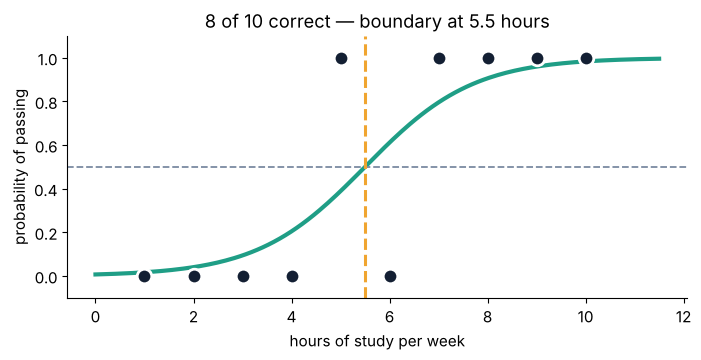

In [10]:
print("accuracy:", (table["we predict"] == table.truth).mean())
print()
g = np.linspace(0, 11.5, 200)
plt.plot(g, sigmoid(w*g + b), color="#1F9E86", lw=3)
plt.axhline(0.5, color="#7B8AA1", lw=1.3, ls="--")
plt.axvline(-b/w, color="#F0A530", lw=2.2, ls="--")
plt.scatter(hours, passed, s=110, color="#131F33", zorder=6, edgecolor="white", lw=2)
plt.ylim(-0.1, 1.1)
plt.xlabel("hours of study per week"); plt.ylabel("probability of passing")
plt.title(f"8 of 10 correct — boundary at {-b/w:.1f} hours")
plt.show()

### The two it gets wrong are the two closest to the boundary

p = 0.389 and p = 0.611. **The model was not confident about either, and it was right not
to be.**

This is why a probability beats a verdict. "Fail" and "fail, probability 0.389" are very
different things to tell a student in week three.

---
# Part 3 · A cost that works

## 3.1 · Picking up from yesterday

You already have:

- a **cost function** is a single number saying how wrong the model is
- **gradient descent** finds the numbers that make it smallest: guess, measure, step
  downhill, repeat

**Today needs one change: the cost function itself.** Squared error was right for
predicting a mark. For predicting a yes or a no it is the wrong tool.

## 3.2 · Why squared error fails here

A student really did pass (truth = 1). Your model gave some probability. How much should
that cost you?

In [11]:
print(f"{'your p':>10}{'squared error':>16}{'log loss':>12}")
print("-" * 38)
for p in [0.9, 0.7, 0.5, 0.3, 0.1, 0.01, 0.001, 0.0001]:
    print(f"{p:>10}{(1-p)**2:>16.4f}{-np.log(p):>12.4f}")

    your p   squared error    log loss
--------------------------------------
       0.9          0.0100      0.1054
       0.7          0.0900      0.3567
       0.5          0.2500      0.6931
       0.3          0.4900      1.2040
       0.1          0.8100      2.3026
      0.01          0.9801      4.6052
     0.001          0.9980      6.9078
    0.0001          0.9998      9.2103


### Squared error has a ceiling of 1. Log loss does not.

Look at the bottom rows. Saying p = 0.1 when the truth was yes costs **0.81**. Saying
p = 0.0001 — being a *thousand times* more confidently wrong — costs **0.9998**.

Barely any difference. Squared error cannot express how bad a confident mistake is,
because **(1 − p)² can never exceed 1**.

Log loss charges **2.30** and **9.21** for those same two guesses.

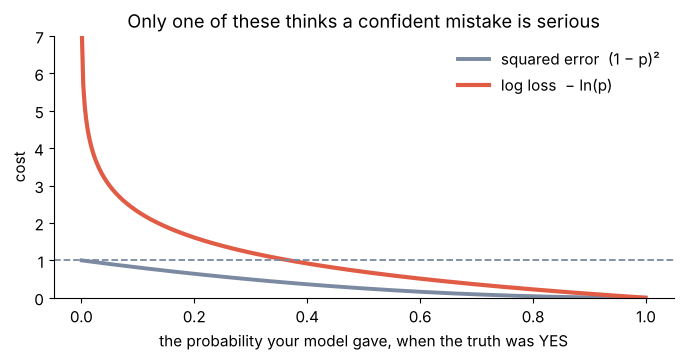

In [12]:
p = np.linspace(0.0008, 0.999, 400)

plt.plot(p, (1-p)**2, color="#7B8AA1", lw=2.8, label="squared error  (1 − p)²")
plt.plot(p, -np.log(p), color="#E05C45", lw=3, label="log loss  − ln(p)")
plt.axhline(1, color="#7B8AA1", lw=1.3, ls="--")
plt.ylim(0, 7)
plt.xlabel("the probability your model gave, when the truth was YES")
plt.ylabel("cost")
plt.legend(frameon=False)
plt.title("Only one of these thinks a confident mistake is serious")
plt.show()

## 3.3 · What that ceiling costs you in practice

100 students. The model is right about 99 of them, and catastrophically wrong about one.

In [13]:
truth = np.ones(100)
guesses = np.append(np.full(99, 0.9), 0.001)     # 99 good calls, 1 disaster

sq = ((truth - guesses) ** 2).mean()
ll = (-np.log(guesses)).mean()

print(f"average squared error : {sq:.4f}")
print(f"average log loss      : {ll:.4f}")
print()
print(f"the one disaster contributes {-np.log(0.001)/100:.4f} of that {ll:.4f}")
print(f"   = {100 * (-np.log(0.001)/100) / ll:.0f}% of the whole cost")

average squared error : 0.0199
average log loss      : 0.1734

the one disaster contributes 0.0691 of that 0.1734
   = 40% of the whole cost


**40% of the total cost comes from a single student.** That is the cost function noticing.

Under squared error that same student is lost in the noise.

### Be honest about what this does and does not prove

If you fit a sigmoid by minimising squared error on clean data, you get **almost the same
curve** as log loss. The argument is **not** that the fit falls apart.

The argument is that squared error **cannot express how bad a confident mistake is** — and
in medicine, credit and fraud, that is exactly the mistake that matters.

## 3.4 · Log loss, written out

$$\text{cost for one row} = \begin{cases} -\ln(p) & \text{if the truth was yes} \\
-\ln(1-p) & \text{if the truth was no} \end{cases}$$

Every row contributes one of the two. Add them up, divide by how many.

*(It is also called **cross-entropy**, and that is the name you will meet in Module 4.)*

In [14]:
def my_log_loss(y_true, p):
    p = np.clip(p, 1e-12, 1 - 1e-12)          # never take ln(0)
    return -(y_true*np.log(p) + (1-y_true)*np.log(1-p)).mean()

our_p = sigmoid(w*hours + b)

print("my version     :", round(my_log_loss(passed, our_p), 6))
print("sklearn version:", round(log_loss(passed, our_p), 6))

my version     : 0.266099
sklearn version: 0.266099


## 3.5 · Gradient descent, exactly as you learned it

There is **no formula** for logistic regression — no shortcut like the one Day 33 had. So
walking downhill is not one option among two. It is the only way.

And the loop is unchanged from yesterday.

In [15]:
def fit_by_hand(x, y, rate=0.1, steps=60000, report=(1, 10, 100, 1000, 10000, 60000)):
    w_, b_ = 0.0, 0.0
    n = len(x)
    for step in range(1, steps + 1):
        p = sigmoid(w_*x + b_)
        error = p - y                            # same shape as always
        w_ -= rate * (1/n) * (error * x).sum()
        b_ -= rate * (1/n) * error.sum()
        if step in report:
            print(f"   step {step:>6}:  w {w_:>7.4f}   b {b_:>8.4f}   "
                  f"log loss {my_log_loss(y, p):.4f}")
    return w_, b_

print("gradient descent:")
gw, gb = fit_by_hand(hours, passed)

gradient descent:
   step      1:  w  0.1150   b   0.0000   log loss 0.6931
   step     10:  w  0.1483   b  -0.1421   log loss 0.6009
   step    100:  w  0.3247   b  -1.2846   log loss 0.4491
   step   1000:  w  0.8950   b  -4.7683   log loss 0.2684


   step  10000:  w  1.2959   b  -7.1256   log loss 0.2509


   step  60000:  w  1.3016   b  -7.1590   log loss 0.2509


### The cost falls from 0.693 to 0.251, and never rises

Notice `error = p - y`. That is the **same expression** as in linear regression — the
gradient of log loss with respect to z works out to exactly the prediction minus the
truth. The maths behind that is beyond today, but the practical consequence is lovely:
**the loop you wrote yesterday needs one change, the sigmoid.**

## 3.6 · One honest note about scikit-learn

In [16]:
no_reg = LogisticRegression(C=1e9).fit(hours.reshape(-1, 1), passed)
default = LogisticRegression().fit(hours.reshape(-1, 1), passed)

print(f"{'how it was fitted':<36}{'w':>10}{'b':>11}{'boundary':>12}")
print("-" * 69)
print(f"{'our own gradient descent':<36}{gw:>10.3f}{gb:>11.3f}{-gb/gw:>12.2f}")
print(f"{'LogisticRegression(C=1e9)':<36}{no_reg.coef_[0][0]:>10.3f}"
      f"{no_reg.intercept_[0]:>11.3f}{-no_reg.intercept_[0]/no_reg.coef_[0][0]:>12.2f}")
print(f"{'LogisticRegression()   <- default':<36}{default.coef_[0][0]:>10.3f}"
      f"{default.intercept_[0]:>11.3f}{-default.intercept_[0]/default.coef_[0][0]:>12.2f}")

how it was fitted                            w          b    boundary
---------------------------------------------------------------------
our own gradient descent                 1.302     -7.159        5.50
LogisticRegression(C=1e9)                1.302     -7.159        5.50
LogisticRegression()   <- default        0.906     -4.983        5.50


### Our loop matches `C=1e9` exactly. The default is different, on purpose.

**scikit-learn applies a little regularization unless you tell it not to.** It
deliberately shrinks the coefficients to stop the model becoming over-confident, which is
why 1.302 becomes 0.906.

Notice the **boundary is identical either way** — 5.50 hours. Only the steepness changed.

On real data the shrunk version usually generalises better. **Regularization gets a full
day on Day 48.** It is flagged now so that when your own gradient descent "disagrees"
with sklearn, you know why.

*(For the rest of today we use the default, 0.906.)*

---
# Part 4 · Reading the answer

## 4.1 · The coefficient is 0.906. It is NOT "+0.906 probability".

Two readings that are wrong, and one that is right.

**Wrong:** "one extra hour adds 0.906 to the probability." Impossible — probabilities stop
at 1, so two extra hours would take you past certainty.

**Also wrong:** "one extra hour adds 90.6 percentage points." Look at the real numbers:

In [17]:
for h in [4, 5, 6, 7, 8]:
    p_now = sigmoid(w*h + b)
    p_next = sigmoid(w*(h+1) + b)
    print(f"   {h} -> {h+1} hours:  p goes {p_now:.3f} -> {p_next:.3f}   "
          f"(a change of {p_next - p_now:+.3f})")

   4 -> 5 hours:  p goes 0.204 -> 0.389   (a change of +0.184)
   5 -> 6 hours:  p goes 0.389 -> 0.611   (a change of +0.223)
   6 -> 7 hours:  p goes 0.611 -> 0.796   (a change of +0.184)
   7 -> 8 hours:  p goes 0.796 -> 0.906   (a change of +0.110)
   8 -> 9 hours:  p goes 0.906 -> 0.960   (a change of +0.054)


**+0.185, +0.222, +0.185, +0.110.** All different. The probability change depends on
where you start.

**Right:** "one extra hour adds 0.906 to the **log-odds**."

## 4.2 · Odds

$$ \text{odds} = \frac{p}{1 - p} $$

A probability of 0.8 is odds of 4 — "four times more likely than not". It is the language
bookmakers and doctors already use.

In [18]:
hh = np.array([4., 5, 6, 7, 8])
pp = sigmoid(w*hh + b)
oo = pp / (1 - pp)

odds_table = pd.DataFrame({
    "hours": hh.astype(int),
    "probability": pp.round(3),
    "odds": oo.round(3),
    # divide the UNROUNDED odds - rounding first would hide the pattern
    "odds ÷ previous": np.r_[np.nan, oo[1:] / oo[:-1]].round(4),
})
odds_table

,hours,probability,odds,odds ÷ previous
0,4,0.204,0.257,NaN
1,5,0.389,0.636,2.4742
2,6,0.611,1.573,2.4742
3,7,0.796,3.891,2.4742
4,8,0.906,9.626,2.4742


### Every single ratio is 2.4742

And where does 2.4742 come from?

In [19]:
print(f"the coefficient    : {w:.6f}")
print(f"e to that power    : {np.exp(w):.6f}")

the coefficient    : 0.905905
e to that power    : 2.474171


### `e^0.906 = 2.474`

> **One extra hour of study multiplies your ODDS of passing by 2.474.**

The same multiplier at every point on the curve. *That* is why the coefficient is worth
quoting — and why we talk about odds instead of probability.

**The model is linear in the log-odds, not in the probability.** That one sentence is the
whole of section 4.

## 4.3 · With two columns, the boundary is a straight line

In [20]:
rng = np.random.default_rng(3501)
N = 800

cgpa        = rng.normal(7.2, 0.9, N).clip(5.0, 10.0).round(2)
internships = rng.poisson(0.9, N).clip(0, 4).astype(float)
backlogs    = rng.poisson(0.7, N).clip(0, 6).astype(float)
mock_score  = rng.normal(6.2, 1.6, N).clip(1, 10).round(1)
branch      = rng.choice(["CSE", "ECE", "MECH"], N, p=[.45, .33, .22])

bump = np.where(branch == "CSE", 0.9, np.where(branch == "ECE", 0.25, 0.0))
z = (-9.6 + 1.05*cgpa + 0.62*internships - 0.55*backlogs + 0.34*mock_score + bump
     + rng.normal(0, 0.45, N))
placed = (rng.uniform(0, 1, N) < sigmoid(z)).astype(int)

campus = pd.DataFrame({"cgpa": cgpa, "internships": internships, "backlogs": backlogs,
                       "mock_score": mock_score, "branch": branch, "placed": placed})
campus.head()

,cgpa,internships,backlogs,mock_score,branch,placed
0,6.85,0.0,1.0,3.5,ECE,0
1,6.08,1.0,0.0,8.4,CSE,1
2,7.65,0.0,1.0,4.2,ECE,0
3,7.72,1.0,0.0,5.8,CSE,1
4,7.25,2.0,1.0,8.4,CSE,1


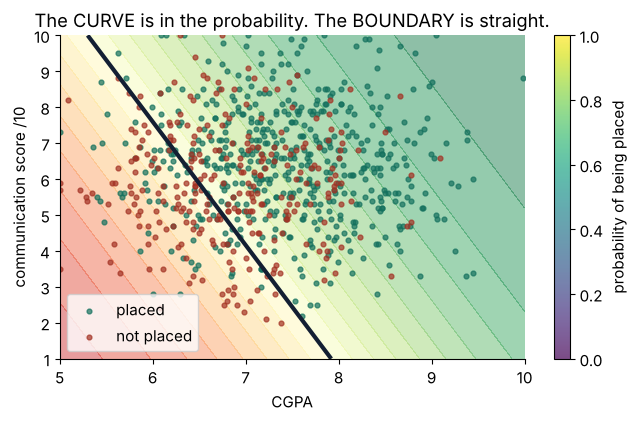

In [21]:
two = LogisticRegression().fit(campus[["cgpa", "mock_score"]], campus.placed)

gx, gy = np.meshgrid(np.linspace(5, 10, 200), np.linspace(1, 10, 200))
pp = two.predict_proba(np.c_[gx.ravel(), gy.ravel()])[:, 1].reshape(gx.shape)

plt.figure(figsize=(7.5, 4.2))
plt.contourf(gx, gy, pp, levels=np.linspace(0, 1, 21), cmap="RdYlGn", alpha=0.45)
plt.contour(gx, gy, pp, levels=[0.5], colors=["#131F33"], linewidths=3)
plt.scatter(campus.cgpa[campus.placed == 1], campus.mock_score[campus.placed == 1],
            s=12, color="#14715E", alpha=0.7, label="placed")
plt.scatter(campus.cgpa[campus.placed == 0], campus.mock_score[campus.placed == 0],
            s=12, color="#A33224", alpha=0.7, label="not placed")
plt.colorbar(label="probability of being placed")
plt.legend(frameon=True, loc="lower left")
plt.xlabel("CGPA"); plt.ylabel("communication score /10")
plt.title("The CURVE is in the probability. The BOUNDARY is straight.")
plt.show()

The shading curves smoothly, but **the black 0.5 line is dead straight**.

That is both why the model is easy to explain, and **the first real limit on what it can
learn**. A problem whose true boundary is a circle is simply out of reach. kNN and trees,
later in the module, can bend.

## 4.4 · The 0.5 cut-off is a choice, not a law

In [22]:
numeric = ["cgpa", "internships", "backlogs", "mock_score"]
encoded = pd.get_dummies(campus[numeric + ["branch"]],
                         columns=["branch"], drop_first=True).astype(float)

X_train, X_hidden, y_train, y_hidden = train_test_split(
    encoded, campus.placed, test_size=0.3, random_state=0, stratify=campus.placed)

full = LogisticRegression(max_iter=2000).fit(X_train, y_train)
probs = full.predict_proba(X_hidden)[:, 1]

print(f"{'cut-off':>9}{'TP':>6}{'FP':>6}{'FN':>6}{'TN':>6}{'accuracy':>11}"
      f"{'right when we say YES':>24}")
print("-" * 68)
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    pred = (probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_hidden, pred).ravel()
    print(f"{t:>9}{tp:>6}{fp:>6}{fn:>6}{tn:>6}{(pred == y_hidden).mean():>11.4f}"
          f"{tp/(tp+fp):>24.4f}")

  cut-off    TP    FP    FN    TN   accuracy   right when we say YES
--------------------------------------------------------------------
      0.3   149    67     7    17     0.6917                  0.6898
      0.4   144    58    12    26     0.7083                  0.7129
      0.5   135    40    21    44     0.7458                  0.7714
      0.6   119    26    37    58     0.7375                  0.8207
      0.7    99    18    57    66     0.6875                  0.8462
      0.8    65     7    91    77     0.5917                  0.9028


### Nothing about the model changed. You changed what you do with it.

Raise the cut-off and you are **right more often when you say yes** (0.69 → 0.90) — but
you **miss more of the people who deserved a yes**.

Which is right depends entirely on the cost of each mistake:

- **A cancer screen:** missing a sick patient is catastrophic, a false alarm means one more
  test. **Lower the cut-off.**
- **A spam filter:** binning a real email is unacceptable. **Raise it.**

## 4.5 · The four ways a yes/no model can be right or wrong

In [23]:
pred = (probs >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_hidden, pred).ravel()

print("                   REALLY placed    REALLY not")
print(f"   we said YES  {tp:>12}{fp:>15}")
print(f"   we said NO   {fn:>12}{tn:>15}")
print()
print(f"   accuracy = ({tp} + {tn}) / {len(y_hidden)} = {(tp+tn)/len(y_hidden):.4f}")
print()
print(f"   The {fn} in the bottom-left are students we told not to bother.")
print("   They would have been placed.")

                   REALLY placed    REALLY not
   we said YES           135             40
   we said NO             21             44

   accuracy = (135 + 44) / 240 = 0.7458

   The 21 in the bottom-left are students we told not to bother.
   They would have been placed.


**Accuracy collapses all four of those boxes into one number** — and the two kinds of
mistake are not the same mistake.

Telling a student who would have been placed not to bother is a very different failure
from telling a student who would not have been placed to keep trying.

**Day 47 is entirely about this table.** Today it is enough to feel that one number is
hiding something.

---
# Part 5 · Doing it for real

## 5.1 · The code

In [24]:
print("coefficients, and what they mean in odds:")
print()
for name, c in zip(encoded.columns, full.coef_[0]):
    print(f"   {name:<22} {c:>+8.4f}   multiply the odds by {np.exp(c):.3f}")
print(f"   {'intercept':<22} {full.intercept_[0]:>+8.4f}")
print()
print(f"accuracy on rows it studied  : {full.score(X_train, y_train):.4f}")
print(f"accuracy on rows it never saw: {full.score(X_hidden, y_hidden):.4f}")
print(f"log loss on hidden rows      : {log_loss(y_hidden, probs):.4f}")

coefficients, and what they mean in odds:

   cgpa                    +1.0442   multiply the odds by 2.841
   internships             +0.5677   multiply the odds by 1.764
   backlogs                -0.5694   multiply the odds by 0.566
   mock_score              +0.2887   multiply the odds by 1.335
   branch_ECE              -0.7116   multiply the odds by 0.491
   branch_MECH             -0.7784   multiply the odds by 0.459
   intercept               -8.2744

accuracy on rows it studied  : 0.7429
accuracy on rows it never saw: 0.7458
log loss on hidden rows      : 0.5246


### Reading those in English

| column | in English |
|---|---|
| `cgpa` **+1.044** | one more CGPA point nearly **triples** the odds (× 2.84) |
| `internships` **+0.568** | each internship raises the odds by **76%** |
| `backlogs` **−0.569** | each backlog **cuts the odds almost in half** (× 0.57) |
| `mock_score` **+0.289** | each point of communication adds **a third** |
| `branch_ECE` **−0.712** | about **half** the odds of a CSE student (the dropped baseline) |

**Every one of those carries the clause from Day 34: holding the other columns constant.**
"Backlogs halve your odds" is only true for two students who match on everything else.

## 5.2 · One student, start to finish

In [25]:
one = {"cgpa": 8.4, "internships": 2, "backlogs": 0, "mock_score": 7.5,
       "branch_ECE": 0.0, "branch_MECH": 0.0}

total = full.intercept_[0]
print(f"{'intercept':<16}{'':>8}   {full.intercept_[0]:>+9.4f}")
for name, c in zip(encoded.columns, full.coef_[0]):
    piece = one[name] * c
    total += piece
    print(f"{name:<16}{one[name]:>8} × {c:>+8.4f} = {piece:>+9.4f}")
print("-" * 46)
print(f"{'z':<16}{'':>8}   {total:>+9.4f}")
print(f"{'p = sigmoid(z)':<16}{'':>8}    {sigmoid(total):>8.4f}")
print()
print("sklearn:", round(full.predict_proba(pd.DataFrame([one])[encoded.columns])[0][1], 4))

intercept                    -8.2744
cgpa                 8.4 ×  +1.0442 =   +8.7716
internships            2 ×  +0.5677 =   +1.1353
backlogs               0 ×  -0.5694 =   -0.0000
mock_score           7.5 ×  +0.2887 =   +2.1649
branch_ECE           0.0 ×  -0.7116 =   -0.0000
branch_MECH          0.0 ×  -0.7784 =   -0.0000
----------------------------------------------
z                            +3.7973
p = sigmoid(z)                0.9781

sklearn: 0.9781


**Multiply, add, squash.** Five multiplications and one exponential, and you can check
every step by hand.

## 5.3 · Which column matters most? Same trap as yesterday.

In [26]:
scaler = StandardScaler().fit(X_train)
scaled = LogisticRegression(max_iter=2000).fit(scaler.transform(X_train), y_train)

compare = pd.DataFrame({
    "column": encoded.columns,
    "raw": full.coef_[0].round(4),
    "scaled": scaled.coef_[0].round(4),
})
compare["rank by raw"] = compare.raw.abs().rank(ascending=False).astype(int)
compare["rank by scaled"] = compare.scaled.abs().rank(ascending=False).astype(int)
compare.sort_values("rank by scaled")

,column,raw,scaled,rank by raw,rank by scaled
0,cgpa,1.0442,0.9070,1,1
1,internships,0.5677,0.5499,5,2
2,backlogs,-0.5694,-0.4648,4,3
3,mock_score,0.2887,0.4498,6,4
5,branch_MECH,-0.7784,-0.3450,2,5
4,branch_ECE,-0.7116,-0.3428,3,6


### `mock_score` is last by raw coefficient and **fourth** once scaled

Its raw coefficient is the smallest in the model (+0.289) — but mock scores run from 1 to
10, while `branch_ECE` can only ever be 0 or 1. A "point" of each is nothing like the same
amount of change.

Exactly the Day 34 lesson, and it does not go away just because the answer became a
category.

## 5.4 · Is 74.6% accuracy any good?

In [27]:
baseline = max(y_hidden.mean(), 1 - y_hidden.mean())

print(f"always say 'placed' to everybody : {baseline:.4f}")
print(f"our model                        : {full.score(X_hidden, y_hidden):.4f}")
print(f"the gap                          : {full.score(X_hidden, y_hidden) - baseline:+.4f}")

always say 'placed' to everybody : 0.6500
our model                        : 0.7458
the gap                          : +0.0958


**65% of these students were placed**, so a model that blindly says "yes" to everyone is
already right about two-thirds of the time.

Quote 74.6% on its own and you sound impressive. Quote it next to 65% and you are being
honest. **The gap is the finding.**

### ⚠️ And this gets much worse with rare events

In [28]:
# 10,000 transactions, 1% of them fraud
fraud = np.zeros(10000)
fraud[:100] = 1

lazy = np.zeros(10000)        # a 'model' that says NEVER FRAUD, always

print(f"accuracy of a model that never flags anything: {(lazy == fraud).mean():.4f}")
print(f"frauds it caught: {int(((lazy == 1) & (fraud == 1)).sum())} out of {int(fraud.sum())}")

accuracy of a model that never flags anything: 0.9900
frauds it caught: 0 out of 100


**99% accurate, and it caught zero frauds.** Accuracy is the wrong question entirely when
one class is rare — that is the **Imbalanced Data** day later in the module.

## 5.5 · One new habit: stratify the split

In [29]:
rare = campus.copy()
rare["flag"] = (rare.cgpa > 9.2).astype(int)      # a deliberately rare class
print("overall rate:", round(rare.flag.mean(), 4), f" ({rare.flag.sum()} rows out of 800)")
print()

for stratify in [None, rare.flag]:
    label = "stratify=y " if stratify is not None else "no stratify"
    spread = []
    for seed in range(8):
        _, _, ytr, yte = train_test_split(rare[["cgpa"]], rare.flag, test_size=0.3,
                                          random_state=seed, stratify=stratify)
        spread.append(yte.mean())
    print(f"{label}: rate in the hidden half across 8 splits -> "
          f"{min(spread):.4f} to {max(spread):.4f}")

overall rate: 0.0112  (9 rows out of 800)

no stratify: rate in the hidden half across 8 splits -> 0.0083 to 0.0167
stratify=y : rate in the hidden half across 8 splits -> 0.0125 to 0.0125


**Without `stratify`, the rate in your hidden half wanders.** With it, every split keeps
the same mix as the full dataset.

With a 50/50 target it rarely matters. With a rare class it matters enormously — and a
rare class is the normal case in fraud, churn and disease.

**One word, and it costs nothing. Make it a reflex.**

## 5.6 · The five steps

In [30]:
#  1 · LOOK — for a category, the first thing you do is COUNT
print("1 · LOOK")
print(campus.placed.value_counts().to_string())
print(f"   baseline to beat: {max(campus.placed.mean(), 1-campus.placed.mean()):.4f}")

#  2 · SPLIT — with stratify
a, b, c, d = train_test_split(encoded, campus.placed, test_size=0.3,
                              random_state=0, stratify=campus.placed)

#  3 · ENCODE — already done with get_dummies above
#  4 · FIT & READ
m = LogisticRegression(max_iter=2000).fit(a, c)
print("\n4 · READ")
print(f"   each internship multiplies the odds by {np.exp(m.coef_[0][1]):.3f}")

#  5 · CHECK
print("\n5 · CHECK")
print(f"   accuracy on hidden rows : {m.score(b, d):.4f}")
print(f"   against a baseline of   : {max(d.mean(), 1-d.mean()):.4f}")

1 · LOOK
placed
1    520
0    280
   baseline to beat: 0.6500

4 · READ
   each internship multiplies the odds by 1.764

5 · CHECK
   accuracy on hidden rows : 0.7458
   against a baseline of   : 0.6500


## 5.7 · Five mistakes everybody makes once

| # | The mistake | What you will see | The fix |
|---|---|---|---|
| 1 | Reading a coefficient as probability | "One hour adds 0.906 to the chance" | Run it through `exp()` — it is odds |
| 2 | Using `.predict()` and never the probability | A verdict with no idea how confident | `.predict_proba()[:, 1]` |
| 3 | Quoting accuracy with no baseline | "74.6%!" when guessing gives 65% | Always report both |
| 4 | Treating 0.5 as fixed | Missing the cases that actually matter | Choose it from the cost of each mistake |
| 5 | Forgetting `stratify=y` | Wild scores on a rare class | Add it. One word |

**Number 1 is the one that ends up in a report. Number 3 is the one that ends up in a
presentation.**

---

# What to remember

| | |
|---|---|
| **A line, then a squash** | `z = w₁x₁ + … + b`, exactly as yesterday. Then `p = 1/(1 + e⁻ᶻ)`, which can never leave 0 to 1 |
| **Squared error has a ceiling** | However confidently wrong you are it can never charge more than 1. Log loss charges 6.91 for a p of 0.001 |
| **Gradient descent, unchanged** | Same loop as yesterday — and this time there is no formula to fall back on, so it is the only route |
| **Coefficients are log-odds** | 0.906 is not probability. `e^0.906 = 2.474`, so one extra hour multiplies the ODDS by 2.474, everywhere on the curve |
| **0.5 is your choice** | The model outputs a probability. The threshold is a business decision and it belongs to you |
| **Accuracy needs a baseline** | 74.6% against 65% for guessing. The gap is the finding |

---

### Tonight

19 practice questions. Part D asks you to write the gradient descent loop yourself — the
one from yesterday, with the sigmoid in it.

### Next

**Day 36 — train/test split and cross-validation.** How to measure any of this honestly.

---
*Slides & notebooks by Srinivasa Sai Chava · Boston University*